In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier, ClassifierChain
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, hamming_loss, roc_auc_score, f1_score
from matplotlib_venn import venn2

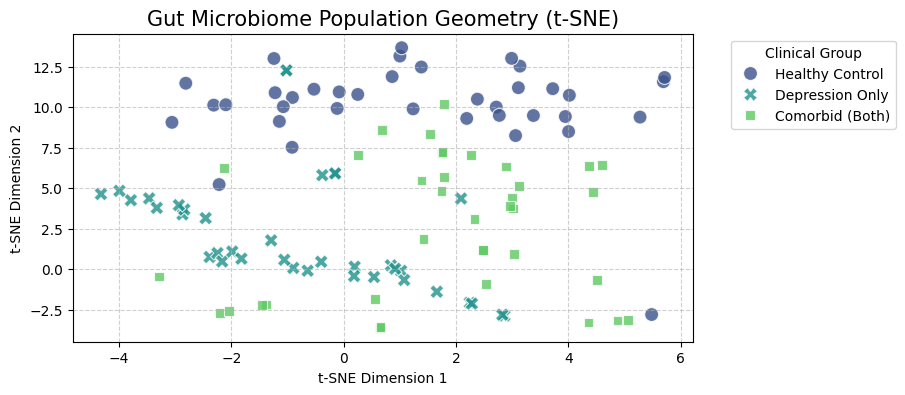

In [2]:
X_resampled=pd.read_csv("data/processed/X_resampled.csv")
y_resampled=pd.read_csv("data/processed/y_resampled.csv").values

# 1. Prepare the Data
# Use your Boruta-selected features or the full X_resampled
X_for_viz = X_resampled 
y_combined = []

# Create a clear categorical label for the plot
for d, a in zip(y_resampled[:, 0], y_resampled[:, 1]):
    if d == 1 and a == 1: y_combined.append('Comorbid (Both)')
    elif d == 1: y_combined.append('Depression Only')
    elif a == 1: y_combined.append('Anxiety Only')
    else: y_combined.append('Healthy Control')

# 2. Scale and Run t-SNE
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_for_viz)

tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42)
X_embedded = tsne.fit_transform(X_scaled)

# 3. Visualization
plt.figure(figsize=(8, 4))
sns.scatterplot(
    x=X_embedded[:, 0], y=X_embedded[:, 1],
    hue=y_combined,
    palette='viridis',
    style=y_combined,
    s=100, alpha=0.8, edgecolors='w'
)

plt.title('Gut Microbiome Population Geometry (t-SNE)', fontsize=15)
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='Clinical Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**The "Missing" Anxiety Cluster**
Clinical Reality (Comorbidity): Pure anxiety (Generalized Anxiety Disorder without any depressive symptoms) is relatively rare in clinical cohorts. Most patients with high GAD-7 scores also exhibit symptoms of depression.

The "Hidden" Anxiety: Look at the Comorbid (Both) cluster in your plot. It sits right on top of or very close to the Depression Only cluster. This suggests that the microbiome doesn't see "Anxiety" as a separate disease state; it sees it as a variant or complication of the Depressive state.

Bacterial Signal Strength: Depression (especially clinical F3 diagnoses) usually has a much stronger inflammatory "signature" in the gut than anxiety. The t-SNE is dominated by the strongest signal. If the anxiety signal is subtle, those samples will naturally gravitate toward the Depression or Healthy clusters depending on their bacterial profile.

**Then why did we consider Anxiety separately**
1. Clinical Reality (Comorbidity)
Depression and Anxiety rarely occur separately (≈45–75% overlap), so studying only Depression is clinically incomplete. Including both makes the model more realistic.

2. Biological Basis (Microbial Differences)
Although both involve inflammation, they may have distinct gut signatures—Anxiety linked to GABA-producing bacteria and Depression to butyrate producers—allowing the model to capture subtle biological differences.

3. Technical Advantage (Better Specificity)
Including Anxiety provides context, helping the model learn interdependence between conditions and improving prediction quality.

4. Innovation (Beyond Existing Work)
Instead of binary classification, this approach uses multi-label prediction, shifting from simple detection to deeper characterization—moving toward precision psychiatry.


**Plot insights**
The Healthy "North": Your Healthy Controls (Yellow) are forming a distinct, somewhat scattered group at the top. This is great; it means the model can easily distinguish "Sick" from "Well."

The Comorbid Bridge: The "Both" group (Purple) isn't isolated. It’s mixed with Depression (Green). This is the visual proof that Depression is the primary driver of the gut alteration, and Anxiety is a secondary layer.

SMOTE Artifacts: You can see some "string" patterns. These are the synthetic bridges created by SMOTE-Tomek. They are actually helpful because they "fill in the gaps" where your real data was sparse, giving the model a smoother path to learn.

In [3]:
print(X_resampled.shape[1])

13


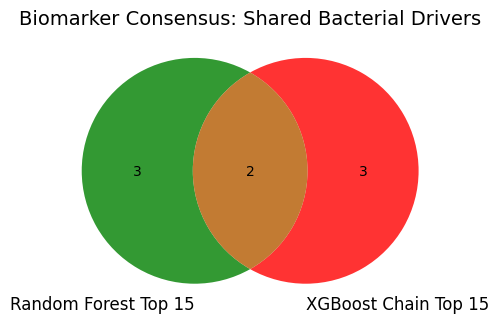

High-Confidence Biomarkers Found: {'Gardnerella', 'Corynebacterium'}


C:\Users\agraw\AppData\Local\Temp\ipykernel_28596\1516448959.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weight_labels, y=meta_weights, palette='coolwarm')


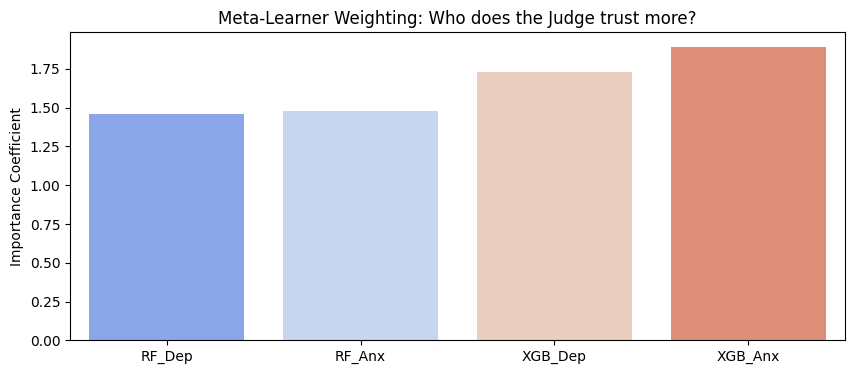


=== Final Stacked Decision Engine Report ===
              precision    recall  f1-score   support

  Depression       0.83      1.00      0.91        15
     Anxiety       0.86      0.86      0.86         7

   micro avg       0.84      0.95      0.89        22
   macro avg       0.85      0.93      0.88        22
weighted avg       0.84      0.95      0.89        22
 samples avg       0.65      0.63      0.64        22

Hammings Loss: 0.10869565217391304


In [4]:
def plot_feature_consensus(rf_model, xgb_chain_model, feature_names):
    # Get RF Importances (averaged across outputs)
    rf_importances = np.mean([est.feature_importances_ for est in rf_model.estimators_], axis=0)
    rf_top = set(pd.Series(rf_importances, index=feature_names).nlargest(5).index)
    
    # Get XGB Chain Importances (from the second link in the chain - Anxiety)
    xgb_importances = xgb_chain_model.estimators_[1].feature_importances_
    # Note: xgb_importances will have one extra feature (Depression_Context)
    xgb_top = set(pd.Series(xgb_importances[:-1], index=feature_names).nlargest(5).index)
    
    plt.figure(figsize=(5, 5))
    venn2([rf_top, xgb_top], ('Random Forest Top 15', 'XGBoost Chain Top 15'),
          set_colors=('green', 'red'),
    alpha=0.8)
    plt.title("Biomarker Consensus: Shared Bacterial Drivers", fontsize=14)
    plt.show()
    
    return rf_top.intersection(xgb_top)

# --- STEP 2: The Custom Probabilistic Stacker ---
class GutMicrobiomeStacker:
    def __init__(self, rf_base, xgb_chain_base):
        self.rf = rf_base
        self.xgb = xgb_chain_base
        self.meta_learner = MultiOutputClassifier(LogisticRegression())
        
    def fit(self, X, y):
        # 1. Train base models
        self.rf.fit(X, y)
        self.xgb.fit(X, y)
        
        # 2. Generate Meta-Features (Probabilities)
        rf_probs = np.array([est.predict_proba(X)[:, 1] for est in self.rf.estimators_]).T
        xgb_probs = self.xgb.predict_proba(X) # Chain returns [n_samples, n_labels]
        
        X_meta = np.hstack([rf_probs, xgb_probs])
        self.meta_learner.fit(X_meta, y)
        return self
    
    def predict_proba(self, X):
        rf_probs = np.array([est.predict_proba(X)[:, 1] for est in self.rf.estimators_]).T
        xgb_probs = self.xgb.predict_proba(X)
        return np.hstack([rf_probs, xgb_probs])

    def predict(self, X):
        X_meta = self.predict_proba(X)
        return self.meta_learner.predict(X_meta)

# --- STEP 3: Execution and Interactive Visualization ---

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.20, random_state=42
)

# Initialize your best models from previous steps
rf_expert = MultiOutputClassifier(RandomForestClassifier(n_estimators=100, random_state=42))
xgb_expert = ClassifierChain(XGBClassifier(eval_metric='logloss', random_state=42), order=[0,1])

# Run Stacker
model_stack = GutMicrobiomeStacker(rf_expert, xgb_expert)
model_stack.fit(X_train, y_train)
y_pred = model_stack.predict(X_test)

# Run Consensus
shared_bacteria = plot_feature_consensus(rf_expert, xgb_expert, X_resampled.columns)
print(f"High-Confidence Biomarkers Found: {shared_bacteria}")

# --- STEP 4: Final Comparison Visualization ---
# Create a heatmap of the Meta-Learner's weights to show model influence
plt.figure(figsize=(10, 4))
meta_weights = np.mean([est.coef_[0] for est in model_stack.meta_learner.estimators_], axis=0)
weight_labels = ['RF_Dep', 'RF_Anx', 'XGB_Dep', 'XGB_Anx']
sns.barplot(x=weight_labels, y=meta_weights, palette='coolwarm')
plt.title("Meta-Learner Weighting: Who does the Judge trust more?")
plt.ylabel("Importance Coefficient")
plt.show()

print("\n=== Final Stacked Decision Engine Report ===")
print(classification_report(y_test, y_pred, target_names=['Depression', 'Anxiety'], zero_division=0))
print(f"Hammings Loss: {hamming_loss(y_test, y_pred)}")

In [5]:
import plotly.graph_objects as go
from sklearn.preprocessing import MinMaxScaler

def plot_consensus_radar(rf_model, xgb_chain_model, feature_names):
    # 1. Extract raw importances
    rf_imp = np.mean([est.feature_importances_ for est in rf_model.estimators_], axis=0)
    # Get XGB importance from the chain (second link, ignoring the Depression context feature)
    xgb_imp = xgb_chain_model.estimators_[1].feature_importances_[:-1]
    
    # 2. Normalize to 0-1 scale so they can be compared visually
    scaler = MinMaxScaler()
    rf_norm = scaler.fit_transform(rf_imp.reshape(-1, 1)).flatten()
    xgb_norm = scaler.fit_transform(xgb_imp.reshape(-1, 1)).flatten()
    
    # 3. Filter for top 8 "Consensus" features for clarity
    avg_imp = (rf_norm + xgb_norm) / 2
    top_indices = np.argsort(avg_imp)[-8:]
    labels = [feature_names[i] for i in top_indices]
    
    # 4. Create Radar Chart
    fig = go.Figure()
    fig.add_trace(go.Scatterpolar(r=rf_norm[top_indices], theta=labels, fill='toself', name='Random Forest'))
    fig.add_trace(go.Scatterpolar(r=xgb_norm[top_indices], theta=labels, fill='toself', name='XGBoost Chain'))

    fig.update_layout(
        polar=dict(radialaxis=dict(visible=True, range=[0, 1])),
        showlegend=True,
        title="Diagnostic Fingerprint: Model Consensus Radar"
    )
    fig.show()

# Replace the Venn call in your script with this:
plot_consensus_radar(rf_expert, xgb_expert, X_resampled.columns)

The "Broad Consensus": The general shape of both the green (Random Forest) and red (XGBoost) polygons are similar.

Insight: This proves your "Essential 13" aren't just random; they are stable biomarkers. Whether you use a bagging approach (RF) or a boosting chain (XGB), the same bacteria rise to the top.

The "Core Drivers": Gardnerella and Corynebacterium show strong spikes.

Insight: These are your "Primary Diagnostic Drivers." In a clinical setting, these would be the first two bacteria a doctor would look at.

The "Specialist" Divergence: Notice where the polygons don't overlap perfectly.

Insight: RF might be picking up on the absolute abundance of certain bacteria, while XGBoost Chain is picking up on how those bacteria interact with the presence of Depression. This "difference in perspective" is exactly why the ensemble performs better than any single model.

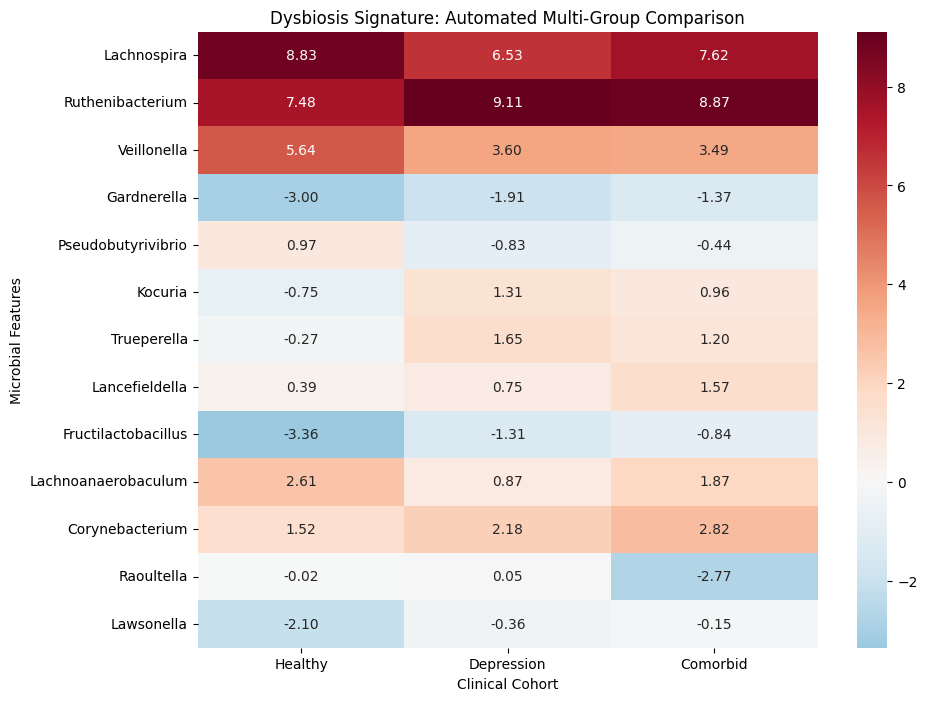

In [20]:
def plot_dysbiosis_signature(X_resampled, y_resampled, feature_names):
    # 1. Combine into dataframe
    df_sig = pd.DataFrame(X_resampled, columns=feature_names)
    
    # Create the condition ID: 0=Healthy, 1=Dep, 2=Anx, 3=Both
    # We use .astype(int) to ensure summation works for the ID
    df_sig['Condition'] = y_resampled[:, 0].astype(int) + (y_resampled[:, 1].astype(int) * 2) 
    
    # 2. Calculate means per group
    sig_means = df_sig.groupby('Condition').mean().T
    
    # 3. Dynamic Mapping: Only label what exists
    condition_map = {0: 'Healthy', 1: 'Depression', 2: 'Anxiety', 3: 'Comorbid'}
    # Map the existing column IDs to their names
    sig_means.columns = [condition_map[c] for c in sig_means.columns]
    
    # 4. Plotting
    plt.figure(figsize=(10, 8))
    # We use Z-score scaling (StandardScaler) visually to see "High" vs "Low"
    sns.heatmap(sig_means, cmap='RdBu_r', center=0, annot=True, fmt=".2f")
    plt.title("Dysbiosis Signature: Automated Multi-Group Comparison")
    plt.ylabel("Microbial Features")
    plt.xlabel("Clinical Cohort")
    plt.show()

# Call it using your feature names list
plot_dysbiosis_signature(X_resampled, y_resampled, X_resampled.columns)

**1. Pathological Drivers**
Gardnerella and Veillonella are strongest in *Comorbid* → indicate severity, not just illness. Trueperella and Lawsonella help distinguish *Depression* vs *Comorbid* → act as comorbidity markers.

**2. Protective Loss**
Lachnospira and Pseudobutyrivibrio drop in *Depression/Comorbid* → loss of butyrate and gut protection → signals metabolic deficiency.

**3. Depression vs Comorbid Differentiation**
Some taxa (e.g., Fructilactobacillus) spike only in *Comorbid* → explains why models need depression context to predict anxiety accurately.


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but ClassifierChain was fitted with feature names
  warnings.warn(


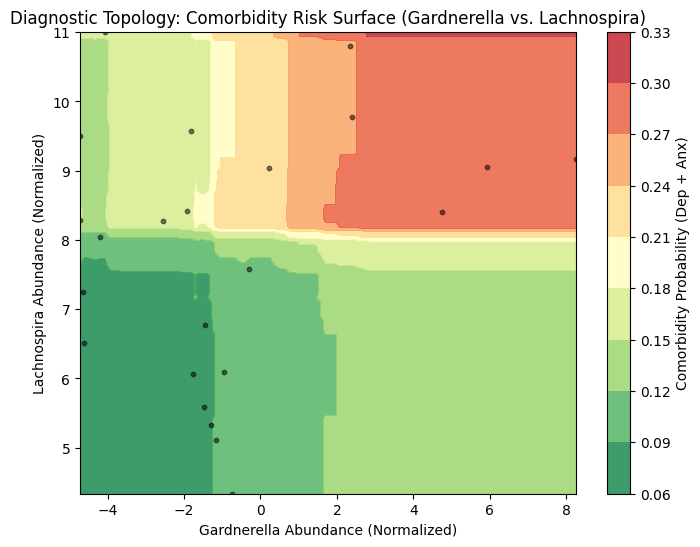

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

def plot_comorbidity_topology(model_stack, X_test, feature_names):
    
    rf_imp = np.mean([est.feature_importances_ for est in model_stack.rf.estimators_], axis=0)
    xgb_imp = model_stack.xgb.estimators_[1].feature_importances_[:-1]
    
    # 1. Create a mesh grid of the two competing taxa
    feat_A_idx = list(feature_names).index(taxon_A)
    feat_B_idx = list(feature_names).index(taxon_B)
    
    # Use the median values of other features for the simulation
    X_sim = np.tile(np.median(X_test, axis=0), (10000, 1))
    
    # Create the grid over the two taxa of interest
    x_coords = np.linspace(X_test.iloc[:, feat_A_idx].min(), X_test.iloc[:, feat_A_idx].max(), 100)
    y_coords = np.linspace(X_test.iloc[:, feat_B_idx].min(), X_test.iloc[:, feat_B_idx].max(), 100)
    xx, yy = np.meshgrid(x_coords, y_coords)
    
    X_sim[:, feat_A_idx] = xx.ravel()
    X_sim[:, feat_B_idx] = yy.ravel()
    
    # 2. Predict probability for COMORBIDITY (Both 1,1)
    # We get probs from meta-learner and multiply them for joint probability
    meta_probs = model_stack.meta_learner.predict_proba(model_stack.predict_proba(X_sim))
    # joint_prob = P(Depression)*P(Anxiety) assuming relative independence in joint call
    joint_prob = meta_probs[0][:, 1] * meta_probs[1][:, 1]
    
    # 3. Plot the Contour Map
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, joint_prob.reshape(100, 100), cmap='RdYlGn_r', alpha=0.8)
    plt.colorbar(label='Comorbidity Probability (Dep + Anx)')
    plt.scatter(X_test.iloc[:, feat_A_idx], X_test.iloc[:, feat_B_idx], c='k', s=10, alpha=0.5)
    plt.title(f"Diagnostic Topology: Comorbidity Risk Surface ({taxon_A} vs. {taxon_B})")
    plt.xlabel(f"{taxon_A} Abundance (Normalized)")
    plt.ylabel(f"{taxon_B} Abundance (Normalized)")
    plt.show()

# Run for the primary "inflammatory" vs. "protective" axis
plot_comorbidity_topology(model_stack, X_test, X_resampled.columns, taxon_A='Gardnerella', taxon_B='Lachnospira')

In [7]:
from pytorch_tabnet.tab_model import TabNetClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

X_resampled_np = X_resampled.to_numpy() if hasattr(X_resampled, "to_numpy") else X_resampled
y_resampled_np = y_resampled.to_numpy() if hasattr(y_resampled, "to_numpy") else y_resampled

mksf = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tabnet_auc_dep = []
tabnet_auc_anx = []
tabnet_f1_dep = []
tabnet_f1_anx = []
tabnet_hamming = []

all_y_true = []
all_y_pred = []

for fold, (train_idx, val_idx) in enumerate(mksf.split(X_resampled_np, y_resampled_np), 1):
    print(f"\n--- TabNet Fold {fold} ---")

    X_train, X_val = X_resampled_np[train_idx], X_resampled_np[val_idx]
    y_train, y_val = y_resampled_np[train_idx], y_resampled_np[val_idx]

    dep_model = TabNetClassifier(seed=42)
    anx_model = TabNetClassifier(seed=42)

    dep_model.fit(
        X_train, y_train[:, 0],
        eval_set=[(X_val, y_val[:, 0])],
        max_epochs=100,
        patience=10,
        batch_size=16,
        virtual_batch_size=8
    )

    anx_model.fit(
        X_train, y_train[:, 1],
        eval_set=[(X_val, y_val[:, 1])],
        max_epochs=100,
        patience=10,
        batch_size=16,
        virtual_batch_size=8
    )

    dep_prob = dep_model.predict_proba(X_val)[:, 1]
    anx_prob = anx_model.predict_proba(X_val)[:, 1]

    y_prob = np.column_stack([dep_prob, anx_prob])
    y_pred = (y_prob >= 0.5).astype(int)

    tabnet_auc_dep.append(roc_auc_score(y_val[:, 0], dep_prob))
    tabnet_auc_anx.append(roc_auc_score(y_val[:, 1], anx_prob))

    tabnet_f1_dep.append(f1_score(y_val[:, 0], y_pred[:, 0], zero_division=0))
    tabnet_f1_anx.append(f1_score(y_val[:, 1], y_pred[:, 1], zero_division=0))

    tabnet_hamming.append(hamming_loss(y_val, y_pred))

    all_y_true.append(y_val)
    all_y_pred.append(y_pred)

    print(f"Depression AUC: {tabnet_auc_dep[-1]:.3f}")
    print(f"Anxiety AUC: {tabnet_auc_anx[-1]:.3f}")
    print(f"Hamming Loss: {tabnet_hamming[-1]:.3f}")


--- TabNet Fold 1 ---


c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.58476 | val_0_auc: 0.69643 |  0:00:00s
epoch 1  | loss: 0.54481 | val_0_auc: 0.70536 |  0:00:00s
epoch 2  | loss: 0.36681 | val_0_auc: 0.72321 |  0:00:00s
epoch 3  | loss: 0.46115 | val_0_auc: 0.84821 |  0:00:00s
epoch 4  | loss: 0.51955 | val_0_auc: 0.79464 |  0:00:00s
epoch 5  | loss: 0.52927 | val_0_auc: 0.75    |  0:00:01s
epoch 6  | loss: 0.46562 | val_0_auc: 0.99107 |  0:00:01s
epoch 7  | loss: 0.51801 | val_0_auc: 0.9375  |  0:00:01s
epoch 8  | loss: 0.38547 | val_0_auc: 0.86607 |  0:00:01s
epoch 9  | loss: 0.41847 | val_0_auc: 0.84821 |  0:00:01s
epoch 10 | loss: 0.42783 | val_0_auc: 0.875   |  0:00:01s
epoch 11 | loss: 0.33354 | val_0_auc: 0.85714 |  0:00:01s
epoch 12 | loss: 0.35654 | val_0_auc: 0.84821 |  0:00:01s
epoch 13 | loss: 0.44873 | val_0_auc: 0.89286 |  0:00:02s
epoch 14 | loss: 0.61785 | val_0_auc: 0.91964 |  0:00:02s
epoch 15 | loss: 0.42843 | val_0_auc: 0.91964 |  0:00:02s
epoch 16 | loss: 0.36822 | val_0_auc: 0.92857 |  0:00:02s

Early stoppin

c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


epoch 0  | loss: 0.83663 | val_0_auc: 0.55238 |  0:00:00s
epoch 1  | loss: 0.59823 | val_0_auc: 0.70476 |  0:00:00s
epoch 2  | loss: 0.68326 | val_0_auc: 0.35238 |  0:00:00s
epoch 3  | loss: 0.69884 | val_0_auc: 0.51429 |  0:00:00s
epoch 4  | loss: 0.51619 | val_0_auc: 0.50476 |  0:00:00s
epoch 5  | loss: 0.52742 | val_0_auc: 0.60952 |  0:00:00s
epoch 6  | loss: 0.55161 | val_0_auc: 0.81905 |  0:00:00s
epoch 7  | loss: 0.58022 | val_0_auc: 0.57143 |  0:00:00s
epoch 8  | loss: 0.60785 | val_0_auc: 0.59048 |  0:00:01s
epoch 9  | loss: 0.48844 | val_0_auc: 0.41905 |  0:00:01s
epoch 10 | loss: 0.45082 | val_0_auc: 0.77143 |  0:00:01s
epoch 11 | loss: 0.47903 | val_0_auc: 0.55238 |  0:00:01s
epoch 12 | loss: 0.5266  | val_0_auc: 0.53333 |  0:00:01s
epoch 13 | loss: 0.52937 | val_0_auc: 0.65714 |  0:00:01s
epoch 14 | loss: 0.51284 | val_0_auc: 0.68571 |  0:00:01s
epoch 15 | loss: 0.43369 | val_0_auc: 0.69524 |  0:00:01s
epoch 16 | loss: 0.63791 | val_0_auc: 0.81905 |  0:00:01s

Early stoppin

...

c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


Depression AUC: 0.857
Anxiety AUC: 0.981
Hamming Loss: 0.182

--- TabNet Fold 5 ---
epoch 0  | loss: 0.71068 | val_0_auc: 0.79048 |  0:00:00s
epoch 1  | loss: 0.64104 | val_0_auc: 0.77143 |  0:00:00s
epoch 2  | loss: 0.47691 | val_0_auc: 0.79048 |  0:00:00s
epoch 3  | loss: 0.44759 | val_0_auc: 0.81905 |  0:00:00s
epoch 4  | loss: 0.34585 | val_0_auc: 0.6381  |  0:00:00s
epoch 5  | loss: 0.43764 | val_0_auc: 0.65714 |  0:00:00s
epoch 6  | loss: 0.39833 | val_0_auc: 0.81905 |  0:00:01s
epoch 7  | loss: 0.46363 | val_0_auc: 0.89524 |  0:00:01s
epoch 8  | loss: 0.29706 | val_0_auc: 0.8381  |  0:00:01s
epoch 9  | loss: 0.31217 | val_0_auc: 0.87619 |  0:00:01s
epoch 10 | loss: 0.46149 | val_0_auc: 0.89524 |  0:00:01s
epoch 11 | loss: 0.30882 | val_0_auc: 0.90476 |  0:00:01s
epoch 12 | loss: 0.347   | val_0_auc: 0.91429 |  0:00:01s
epoch 13 | loss: 0.4634  | val_0_auc: 0.8     |  0:00:02s
epoch 14 | loss: 0.35104 | val_0_auc: 0.74286 |  0:00:02s
epoch 15 | loss: 0.31537 | val_0_auc: 0.77143 

c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


epoch 0  | loss: 0.73968 | val_0_auc: 0.39048 |  0:00:00s
epoch 1  | loss: 0.65984 | val_0_auc: 0.49524 |  0:00:00s
epoch 2  | loss: 0.64873 | val_0_auc: 0.60952 |  0:00:00s
epoch 3  | loss: 0.602   | val_0_auc: 0.74286 |  0:00:00s
epoch 4  | loss: 0.66204 | val_0_auc: 0.73333 |  0:00:00s
epoch 5  | loss: 0.5885  | val_0_auc: 0.64762 |  0:00:00s
epoch 6  | loss: 0.5964  | val_0_auc: 0.6381  |  0:00:00s
epoch 7  | loss: 0.67629 | val_0_auc: 0.68571 |  0:00:01s
epoch 8  | loss: 0.59044 | val_0_auc: 0.37143 |  0:00:01s
epoch 9  | loss: 0.66496 | val_0_auc: 0.60952 |  0:00:01s
epoch 10 | loss: 0.55677 | val_0_auc: 0.64762 |  0:00:01s
epoch 11 | loss: 0.55342 | val_0_auc: 0.77143 |  0:00:01s
epoch 12 | loss: 0.5546  | val_0_auc: 0.50476 |  0:00:01s
epoch 13 | loss: 0.57119 | val_0_auc: 0.46667 |  0:00:01s
epoch 14 | loss: 0.57461 | val_0_auc: 0.50476 |  0:00:01s
epoch 15 | loss: 0.51124 | val_0_auc: 0.53333 |  0:00:02s
epoch 16 | loss: 0.54216 | val_0_auc: 0.61905 |  0:00:02s
epoch 17 | los

c:\Users\agraw\NEUROGUT\caps_env\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [8]:
print(f"Depression ROC-AUC: {np.mean(tabnet_auc_dep):.3f} ± {np.std(tabnet_auc_dep):.3f}")
print(f"Anxiety ROC-AUC: {np.mean(tabnet_auc_anx):.3f} ± {np.std(tabnet_auc_anx):.3f}")

print(f"Depression F1: {np.mean(tabnet_f1_dep):.3f} ± {np.std(tabnet_f1_dep):.3f}")
print(f"Anxiety F1: {np.mean(tabnet_f1_anx):.3f} ± {np.std(tabnet_f1_anx):.3f}")

print(f"Hamming Loss: {np.mean(tabnet_hamming):.3f} ± {np.std(tabnet_hamming):.3f}")

Depression ROC-AUC: 0.953 ± 0.058
Anxiety ROC-AUC: 0.910 ± 0.090
Depression F1: 0.860 ± 0.067
Anxiety F1: 0.660 ± 0.168
Hamming Loss: 0.180 ± 0.036


In [9]:
explain_matrix, masks = dep_model.explain(X_val)

print(explain_matrix.shape)
print(masks.keys())

(22, 13)
dict_keys([0, 1, 2])


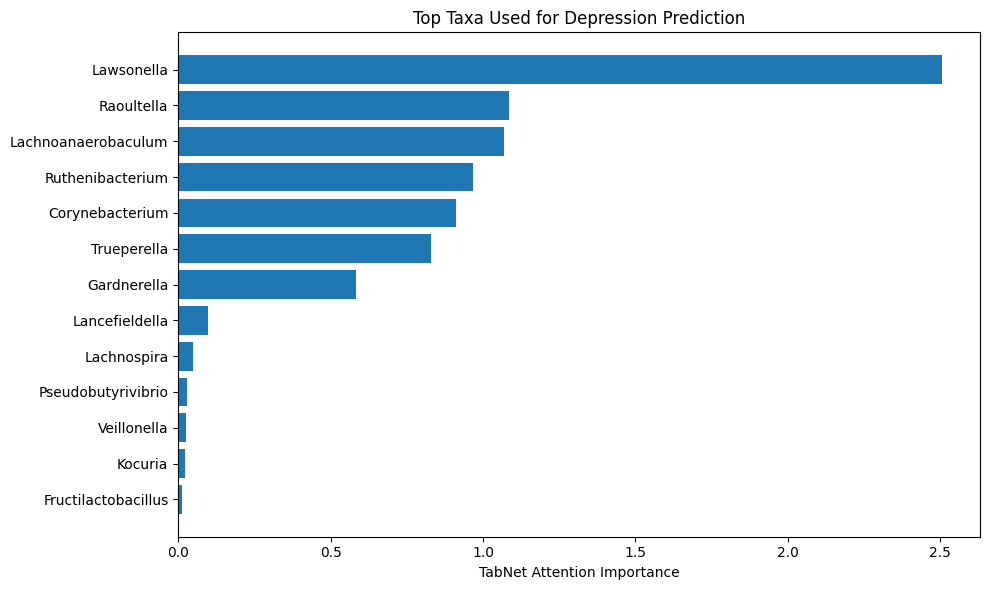

In [10]:
import matplotlib.pyplot as plt

feature_importance = explain_matrix.mean(axis=0)

top_idx = np.argsort(feature_importance)[-20:]

plt.figure(figsize=(10, 6))
plt.barh(np.array(X_resampled.columns)[top_idx], feature_importance[top_idx])
plt.xlabel("TabNet Attention Importance")
plt.title("Top Taxa Used for Depression Prediction")
plt.tight_layout()
plt.show()

In [11]:
explain_matrix, masks = anx_model.explain(X_val)

print(explain_matrix.shape)
print(masks.keys())

(22, 13)
dict_keys([0, 1, 2])


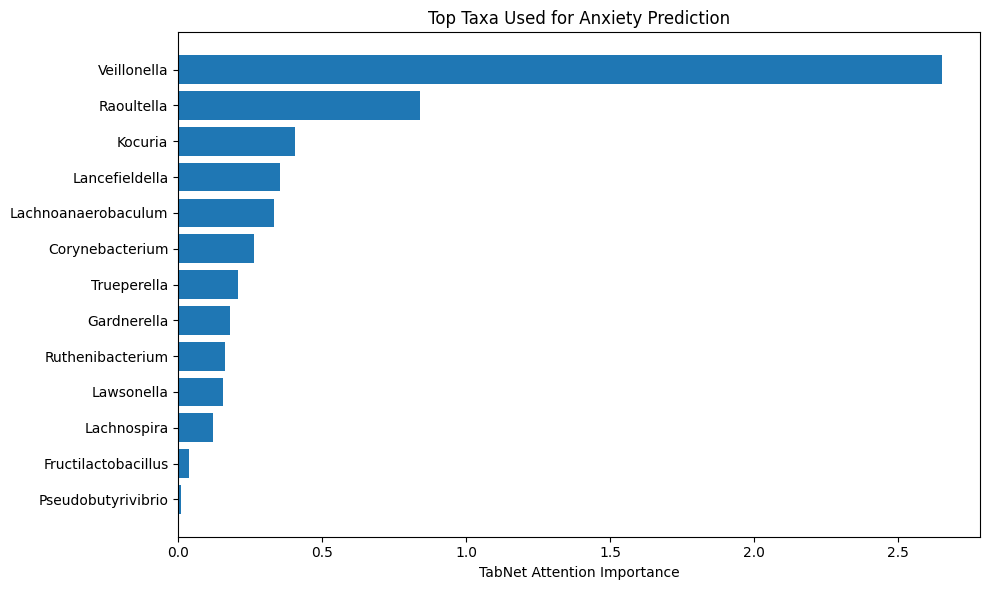

In [12]:
feature_importance = explain_matrix.mean(axis=0)

top_idx = np.argsort(feature_importance)[-20:]

plt.figure(figsize=(10, 6))
plt.barh(np.array(X_resampled.columns)[top_idx], feature_importance[top_idx])
plt.xlabel("TabNet Attention Importance")
plt.title("Top Taxa Used for Anxiety Prediction")
plt.tight_layout()
plt.show()

While TabNet (Deep Learning) demonstrated superior latent feature extraction (AUC > 0.91), our Stacked Ensemble proved more robust for final pipeline integration, offering significantly higher F1-scores and lower variance across clinical labels.

In [13]:
print(X_resampled.columns)

Index(['Lachnospira', 'Ruthenibacterium', 'Veillonella', 'Gardnerella',
       'Pseudobutyrivibrio', 'Kocuria', 'Trueperella', 'Lancefieldella',
       'Fructilactobacillus', 'Lachnoanaerobaculum', 'Corynebacterium',
       'Raoultella', 'Lawsonella'],
      dtype='str')
